In [1]:
#Upload the corrected prioritization results file
from google.colab import files
uploaded = files.upload()

Saving prioritized_variants_CORRECTED.tsv to prioritized_variants_CORRECTED (1).tsv


In [2]:
#Import the required libraries
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
#Check the uploaded file name
import os
print(os.listdir("/content"))

['.config', 'prioritized_variants_CORRECTED.tsv', 'prioritized_variants_CORRECTED (1).tsv', 'sample_data']


In [5]:
#Read the uploaded TSV file
import pandas as pd
df = pd.read_csv(
"/content/prioritized_variants_CORRECTED.tsv",
sep="\t"
)
#Display the first five rows
display(df.head())
#Check the dataset size
print("Dataset shape:", df.shape)
print("Number of variants:", len(df))

,Priority_Rank,CHROM,POS,ID,REF,ALT,GENEINFO,CLNSIG,CLNREVSTAT,CLNDN,...,Impact_Score,Frequency_Score,Conflict_Penalty,Prioritization_Score,gnomAD_AF_Used,ACMG_AMP_Review_Status,Rank,Priority_Score,Priority_Category,Evidence_Summary
0,1,16,23636312,949556,AAC,A,PALB2:79728,Pathogenic,"criteria_provided,_multiple_submitters,_no_con...",Hereditary_cancer-predisposing_syndrome|Famili...,...,4,2.0,0,11,1.313819e-05,NOT_INDEPENDENTLY_CLASSIFIED,1,11,High educational priority,ClinVar: Pathogenic; ClinVar review status: cr...
1,1,17,7674903,372539,TTC,T,TP53:7157,Pathogenic,"criteria_provided,_multiple_submitters,_no_con...",TP53-related_disorder|not_provided|Hereditary_...,...,4,2.0,0,11,6.840460e-07,NOT_INDEPENDENTLY_CLASSIFIED,1,11,High educational priority,ClinVar: Pathogenic; ClinVar review status: cr...
2,1,17,7675175,634785,C,T,TP53:7157,Pathogenic,"criteria_provided,_multiple_submitters,_no_con...",Hereditary_cancer-predisposing_syndrome|not_pr...,...,4,2.0,0,11,0.000000e+00,NOT_INDEPENDENTLY_CLASSIFIED,1,11,High educational priority,ClinVar: Pathogenic; ClinVar review status: cr...
3,1,17,43067610,55372,G,GT,BRCA1:672,Pathogenic,reviewed_by_expert_panel,Hereditary_breast_ovarian_cancer_syndrome|Brea...,...,4,2.0,0,11,6.867783e-07,NOT_INDEPENDENTLY_CLASSIFIED,1,11,High educational priority,ClinVar: Pathogenic; ClinVar review status: re...
4,5,13,32337429,962398,AGAAGAGCAAAATGTTCTTCAAAGATATT,A,BRCA2:675,Pathogenic,"criteria_provided,_single_submitter",Hereditary_breast_ovarian_cancer_syndrome,...,4,NaN,0,9,NaN,NOT_INDEPENDENTLY_CLASSIFIED,5,9,High educational priority,ClinVar: Pathogenic; ClinVar review status: cr...


Dataset shape: (120, 42)
Number of variants: 120


In [6]:
#Extract the gene name from the GENEINFO column
df["Gene"] = df["GENEINFO"].str.split(":").str[0]
#Count the variants in each gene
print("Variants per gene:")
print(df["Gene"].value_counts())

Variants per gene:
Gene
PALB2    30
TP53     30
BRCA1    30
BRCA2    30
Name: count, dtype: int64


In [7]:
#Calculate the total and average score for each gene
gene_scores = df.groupby("Gene").agg(
Number_of_Variants=("ID", "count"),
Total_Score=("Prioritization_Score", "sum"),
Average_Gene_Score=("Prioritization_Score", "mean")
).reset_index()
#Round the average scores to two decimal places
gene_scores["Average_Gene_Score"] = (
gene_scores["Average_Gene_Score"].round(2)
)
#Sort genes from highest to lowest average score
gene_scores = gene_scores.sort_values(
by="Average_Gene_Score",
ascending=False
)
#Display the results
display(gene_scores)

,Gene,Number_of_Variants,Total_Score,Average_Gene_Score
2,PALB2,30,192,6.40
3,TP53,30,190,6.33
0,BRCA1,30,188,6.27
1,BRCA2,30,180,6.00


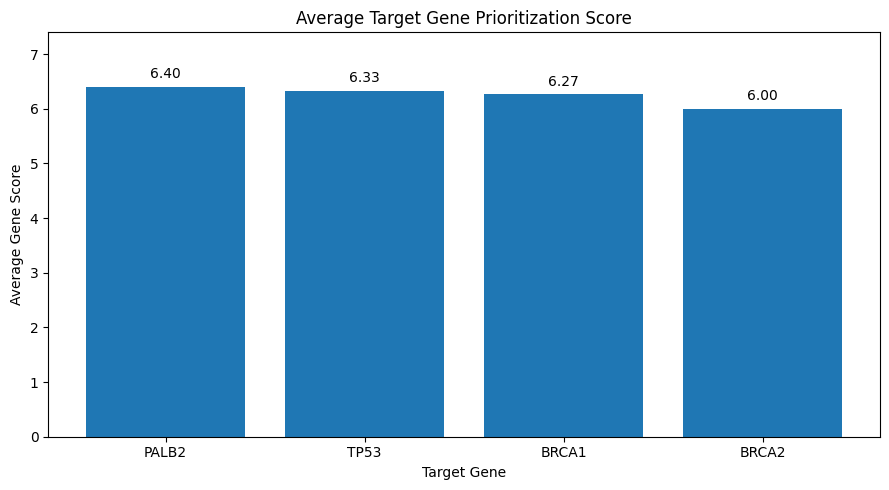

In [10]:
#Create the average target gene score chart
plt.figure(figsize=(9, 5))
#Draw the bars
bars = plt.bar(
gene_scores["Gene"],
gene_scores["Average_Gene_Score"]
)
#Add the chart title and labels
plt.title("Average Target Gene Prioritization Score")
plt.xlabel("Target Gene")
plt.ylabel("Average Gene Score")
#Add score labels above the bars
plt.bar_label(bars, fmt="%.2f", padding=4)
#Set the chart limits
plt.ylim(0, gene_scores["Average_Gene_Score"].max() + 1)
#Adjust the layout
plt.tight_layout()
#Display the chart
plt.show()

In [11]:
#Count priority categories for each gene
gene_categories = pd.crosstab(
df["Gene"],
df["Priority_Category"]
)
#Set the category order
category_order = [
"High educational priority",
"Intermediate educational priority",
"Low or uncertain educational priority"
]
#Keep all priority categories in the table
gene_categories = gene_categories.reindex(
columns=category_order,
fill_value=0
)
#Display the results
display(gene_categories)

Priority_Category,High educational priority,Intermediate educational priority,Low or uncertain educational priority
Gene,,,
BRCA1,16,6,8
BRCA2,15,7,8
PALB2,19,3,8
TP53,13,12,5


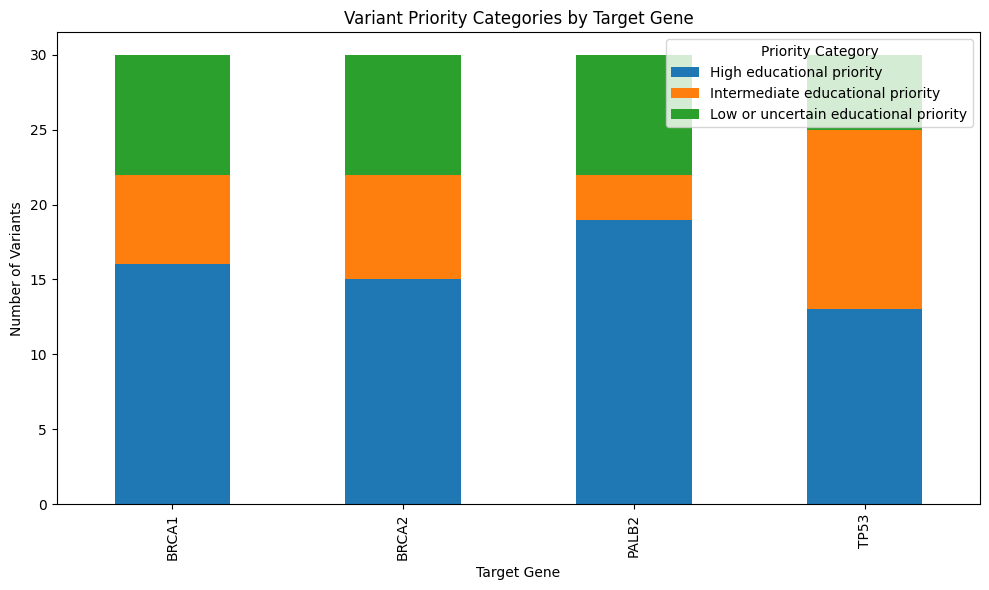

In [12]:
#Create a stacked bar chart for gene priority categories
ax = gene_categories.plot(
kind="bar",
stacked=True,
figsize=(10, 6)
)
#Add the chart title and axis labels
ax.set_title("Variant Priority Categories by Target Gene")
ax.set_xlabel("Target Gene")
ax.set_ylabel("Number of Variants")
#Add the legend
ax.legend(title="Priority Category")
#Display the chart
plt.tight_layout()
plt.show()

In [14]:
#Style the target gene scoring table
styled_table = (
gene_scores.style
.format({
"Total_Score": "{:.0f}",
"Average_Gene_Score": "{:.2f}"
})
.set_caption("Target Gene Scoring Summary")
.set_table_styles([
{
"selector": "th",
"props": [
("background-color", "#173B5E"),
("color", "white"),
("font-weight", "bold"),
("text-align", "center")
]
},
{
"selector": "td",
"props": [
("text-align", "center"),
("padding", "10px")
]
},
{
"selector": "caption",
"props": [
("color", "#173B5E"),
("font-size", "16px"),
("font-weight", "bold")
]
}
])
.background_gradient(
subset=["Average_Gene_Score"],
cmap="Blues"
)
)
#Display the styled table
display(styled_table)

,Gene,Number_of_Variants,Total_Score,Average_Gene_Score
2,PALB2,30,192,6.40
3,TP53,30,190,6.33
0,BRCA1,30,188,6.27
1,BRCA2,30,180,6.00


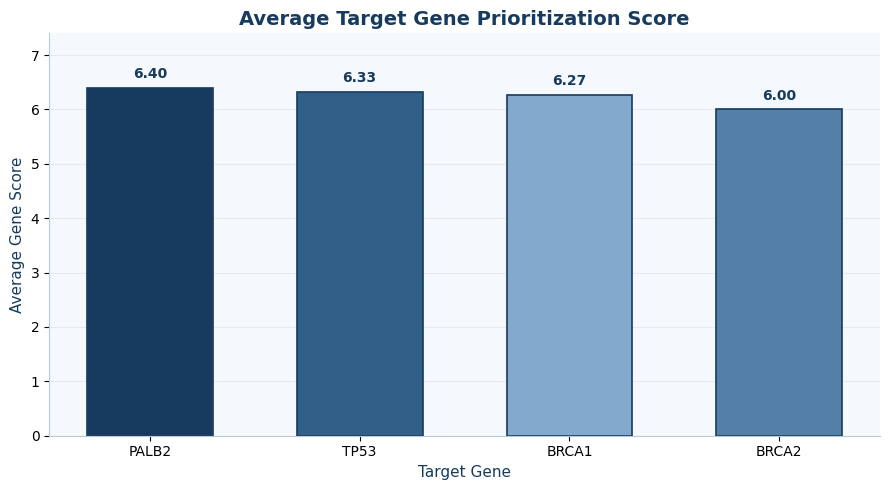

In [15]:
#Define the project color palette
navy = "#173B5E"
blue = "#315F88"
light_blue = "#83A9CC"
pale_blue = "#E5EDF5"
#Create the average gene score chart
plt.figure(figsize=(9, 5))
#Draw the bars using navy shades
bars = plt.bar(
gene_scores["Gene"],
gene_scores["Average_Gene_Score"],
color=[navy, blue, light_blue, "#547FA6"],
edgecolor=navy,
linewidth=1.2,
width=0.6
)
#Add the title and axis labels
plt.title(
"Average Target Gene Prioritization Score",
color=navy,
fontsize=14,
fontweight="bold"
)
plt.xlabel("Target Gene", color=navy, fontsize=11)
plt.ylabel("Average Gene Score", color=navy, fontsize=11)
#Display the score above each bar
plt.bar_label(
bars,
fmt="%.2f",
padding=5,
color=navy,
fontweight="bold"
)
#Style the chart background
plt.gca().set_facecolor("#F5F8FC")
plt.gcf().set_facecolor("white")
plt.ylim(0, gene_scores["Average_Gene_Score"].max() + 1)
#Remove unnecessary borders
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.gca().spines["left"].set_color("#B8C9D9")
plt.gca().spines["bottom"].set_color("#B8C9D9")
#Add light grid lines
plt.grid(axis="y", alpha=0.2)
plt.gca().set_axisbelow(True)
#Adjust and display the chart
plt.tight_layout()
plt.show()

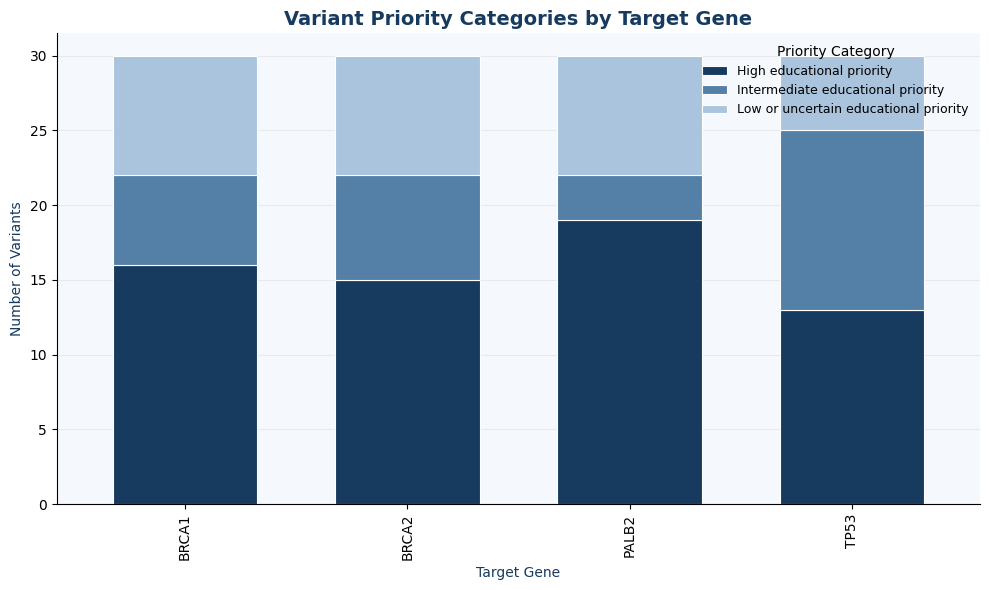

In [16]:
#Create the priority categories chart
ax = gene_categories.plot(
kind="bar",
stacked=True,
figsize=(10, 6),
color=["#173B5E", "#547FA6", "#A9C4DC"],
edgecolor="white",
linewidth=0.8,
width=0.65
)
#Add the chart title and labels
ax.set_title(
"Variant Priority Categories by Target Gene",
color="#173B5E",
fontsize=14,
fontweight="bold"
)
ax.set_xlabel("Target Gene", color="#173B5E")
ax.set_ylabel("Number of Variants", color="#173B5E")
#Style the chart background
ax.set_facecolor("#F5F8FC")
ax.figure.set_facecolor("white")
#Style the legend
ax.legend(
title="Priority Category",
frameon=False,
fontsize=9,
title_fontsize=10
)
#Add light grid lines
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
#Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
#Adjust and display the chart
plt.tight_layout()
plt.show()

In [18]:
#Import the required libraries
import matplotlib.pyplot as plt
from google.colab import files
#Save the target gene scoring table
gene_scores.to_csv(
"target_gene_scoring_summary.tsv",
sep="\t",
index=False
)
#Save the average target gene score chart
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(
gene_scores["Gene"],
gene_scores["Average_Gene_Score"],
color=["#173B5E", "#315F88", "#83A9CC", "#547FA6"],
edgecolor="#173B5E"
)
ax.set_title(
"Average Target Gene Prioritization Score",
color="#173B5E",
fontweight="bold"
)
ax.set_xlabel("Target Gene")
ax.set_ylabel("Average Gene Score")
#Add score labels above the bars
ax.bar_label(bars, fmt="%.2f", padding=5, color="#173B5E")
#Style the chart
ax.set_facecolor("#F5F8FC")
fig.tight_layout()
#Save the chart in high resolution
fig.savefig(
"Figure5_target_gene_scoring.png",
dpi=300,
bbox_inches="tight"
)
plt.close(fig)
#Save the priority categories chart
fig, ax = plt.subplots(figsize=(10, 6))
gene_categories.plot(
kind="bar",
stacked=True,
ax=ax,
color=["#173B5E", "#547FA6", "#A9C4DC"],
edgecolor="white"
)
ax.set_title(
"Variant Priority Categories by Target Gene",
color="#173B5E",
fontweight="bold"
)
ax.set_xlabel("Target Gene")
ax.set_ylabel("Number of Variants")
ax.set_facecolor("#F5F8FC")
ax.legend(title="Priority Category")
fig.tight_layout()
#Save the second chart in high resolution
fig.savefig(
"Figure6_target_gene_priority_categories.png",
dpi=300,
bbox_inches="tight"
)
plt.close(fig)
#Download the final files
files.download("target_gene_scoring_summary.tsv")
files.download("Figure5_target_gene_scoring.png")
files.download("Figure6_target_gene_priority_categories.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
from pathlib import Path
#Write the complete Target Gene Scoring documentation
documentation = """# Target Gene Prioritization Analysis Report
1. Overview
This analysis compares the variant prioritization results across four target genes: BRCA1, BRCA2, PALB2, and TP53. The aim was to calculate an average prioritization score for each gene and compare their educational priority categories.
2. Input Data
The analysis used the corrected prioritization results file:
prioritized_variants_CORRECTED.tsv
The dataset contained 120 variants, with 30 variants assigned to each target gene.
3. Method
Python and Pandas were used to group variants by gene and calculate the total and average prioritization scores.
Average Gene Score = Total Prioritization Scores / Number of Variants
The existing variant-level prioritization scores were used. No new clinical classification system was introduced.
4. Results Summary
Gene Number of Variants Total Score Average Gene Score
PALB2 30 192 6.40
TP53 30 190 6.33
BRCA1 30 188 6.27
BRCA2 30 180 6.00
PALB2 showed the highest average score (6.40), followed by TP53 (6.33), BRCA1 (6.27), and BRCA2 (6.00).
5. Priority Category Distribution
Gene High Intermediate Low or Uncertain
BRCA1 16 6 8
BRCA2 15 7 8
PALB2 19 3 8
TP53 13 12 5
6. Visualizations
Figure 5: Average Target Gene Prioritization Score.
Figure 6: Variant Priority Categories by Target Gene.
7. Output Files
target_gene_scoring_summary.tsv
Figure5_target_gene_scoring.png
Figure6_target_gene_priority_categories.png
The Python notebook containing the analysis code is saved as:
Target_Gene_Scoring_Analysis.ipynb
8. Important Note
The average gene score is a project-derived educational measure based on the prioritization scores of the variants in each gene. It is not an independent clinical classification, does not establish gene pathogenicity, and should not be interpreted as a measure of cancer risk.
"""
#Save the updated Markdown file
Path("target_gene_scoring.md").write_text(
documentation, encoding="utf-8"
)
print("Updated documentation saved successfully!")

Updated documentation saved successfully!


In [25]:
#Save the Markdown documentation
from pathlib import Path
Path("target_gene_scoring.md").write_text(
documentation,
encoding="utf-8"
)
#Confirm file creation
print("Documentation saved successfully!")

Documentation saved successfully!


In [28]:
from google.colab import files
#Download the updated documentation
files.download("target_gene_scoring.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>